In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
warnings.filterwarnings('ignore')

In [4]:
ntl_1053 =  pd.read_csv("C:\\Users\Devesh\\prediction_engine\\NTL_1053_1.csv")

In [5]:
ntl_1186 = pd.read_csv("C:\\Users\\Devesh\\prediction_engine\\Combined_model\\1186_ntl.csv")

In [6]:
ntl_1183 = pd.read_csv("C:\\Users\\Devesh\\prediction_engine\\Combined_model\\1183_ntl.csv")

In [7]:
ntl_1053.head()

,SUBJID,AGE,TRTDOSE,CHEMOICD,B_LESNM,B_LESNMT,B_LESNMN,B_METANM,B_ECOGCD,DOSREFDY,DOSREFWK,LSNO,LSEXAMNO,LSRI,LSSLD_PCT_CHANGE,LSSLD_Change,SEX_Male,RACCAT_Other,RACCAT_White or Caucasian,TRT_panit. plus bevacizumab with chemotherapy,ATRT_panit. plus bevacizumab with chemotherapy,CHEMO_Oxaliplatin,CHEMOI_Oxaliplatin,ACHEMO_Oxaliplatin,ACHEMM_Oxaliplatin,FCHEMO_Oxaliplatin,B_METACT_>1,BMETACTI_>1,PRADJYN_Y,PRADJI_Y,B_LDHYN_Y,B_ECOG_Symptoms but ambulatory,B_ECOGI_Symptoms but ambulatory,DIAGTYPE_Rectal,DIAGI_Rectal,EVALPP_Y,PDPROMED_Y,PDYN_Y,KRAS_Mutant,KRAS_Wild-type,EVALKEA_Y,EVALKSA_Y,EVALKUE_Y,PHASE_Pre-consent,PHASE_Pre-treatment,PHASE_Treatment,LSSITE_Bone,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_Genitourinary/Reproductive,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Rectal,LSSITE_Respiratory,LSSITE_Retroperitoneum,LSSITE_Skin,LSSITE_Spleen,LSPROC_CT chest,LSPROC_CT neck,LSPROC_CT pelvis,LSRAW_Ascites,LSRAW_Bilateral M. or L. Cervical Adenopathy,LSRAW_Bilateral Adrenal,LSRAW_Bilateral Axillary Adenopathy,LSRAW_Bilateral Breast,LSRAW_Bilateral Common Iliac Adenopathy,LSRAW_Bilateral Gonadal mass/nodule,LSRAW_Bilateral Hilar Adenopathy,LSRAW_Bilateral Inguinal Adenopathy,LSRAW_Bilateral Kidney mass/nodule,LSRAW_Bilateral Lung mass/nodule,LSRAW_Bilateral Mediastinal Adenopathy,LSRAW_Bilateral Para-Aortic Adenopathy,LSRAW_Bilateral Paratracheal Adenopathy,LSRAW_Bilateral Pelvic Mass,LSRAW_Bladder,LSRAW_Bone mass/nodule,LSRAW_Celiac Adenopathy,LSRAW_Colon mass/nodule,LSRAW_Esophagus mass/nodule,LSRAW_Left Adrenal,LSRAW_Left Common Iliac Adenopathy,LSRAW_Left External Iliac Adenopathy,LSRAW_Left Hilar Adenopathy,LSRAW_Left Inguinal Adenopathy,LSRAW_Left Kidney mass/nodule,LSRAW_Left Lung mass/nodule,LSRAW_Left Mediastinal Adenopathy,LSRAW_Left Para-Aortic Adenopathy,LSRAW_Left Pelvic Mass,LSRAW_Left Pleural Effusion,LSRAW_Left Supraclavicular Adenopathy,LSRAW_Liver mass/nodule,LSRAW_Lumbar Spine mass/nodule,LSRAW_Mesenteric Adenopathy,LSRAW_Muscular mass/nodule,LSRAW_Other,LSRAW_Pancreas mass/nodule,LSRAW_Pelvic Adenopathy,LSRAW_Pericardial Effusion,LSRAW_Peritoneal mass/nodule,LSRAW_Pleural mass/nodule,LSRAW_Portal Adenopathy,LSRAW_Rectum,LSRAW_Retrocrural Adenopathy,LSRAW_Retroperitoneum,LSRAW_Right Adrenal,LSRAW_Right Axillary Adenopathy,LSRAW_Right Common Iliac Adenopathy,LSRAW_Right External Iliac Adenopathy,LSRAW_Right Hilar Adenopathy,LSRAW_Right Inguinal Adenopathy,LSRAW_Right Lung mass/nodule,LSRAW_Right Mediastinal Adenopathy,LSRAW_Right Para-Aortic Adenopathy,LSRAW_Right Paratracheal Adenopathy,LSRAW_Right Pelvic Mass,LSRAW_Right Pleural Effusion,LSRAW_Right Pleural Mass,LSRAW_Sacrum mass/nodule,LSRAW_Small Bowel mass/nodule,LSRAW_Spleen mass/nodule,LSRAW_Stomach mass/nodule,LSRAW_Sub-Carinal Adenopathy,LSRAW_Subcutaneous mass/nodule,LSRAW_Thoracic Adenopathy,LSRAW_Thoracic Spine mass/nodule,LSNEWANY_Y
0,249101001,67.0,6.0,78.0,100.0,1.0,99.0,1.0,0.0,-8.0,-2.0,202.0,2.0,7.0,60.784314,1,0,0,0,1,1,1,1,1,1,1,0,0,1,1,0,0,0,0,0,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,249101001,67.0,6.0,78.0,100.0,1.0,99.0,1.0,0.0,-2.0,-1.0,201.0,1.0,5.0,60.784314,1,0,0,0,1,1,1,1,1,1,1,0,0,1,1,0,0,0,0,0,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,249101001,67.0,6.0,78.0,100.0,1.0,99.0,1.0,0.0,-2.0,-1.0,200.0,1.0,5.0,60.784314,1,0,0,0,1,1,1,1,1,1,1,0,0,1,1,0,0,0,0,0,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,249101002,72.0,0.0,78.0,101.0,2.0,99.0,2.0,1.0,-12.0,-2.0,201.0,2.0,7.5,25.602410,0,1,0,1,0,0,1,1,1,1,1,1,1,0,0,0,1,1,0,0,1,0,0,1,0,1,1,0,1,0,0

In [8]:
ntl_1186 = pd.get_dummies(ntl_1186, columns=['LSSITE'], drop_first=True, prefix_sep='_')

In [9]:
ntl_1186 = pd.get_dummies(ntl_1186, columns=['SEXCD_x'], drop_first=True, prefix_sep='_')

In [10]:
ntl_1186 = pd.get_dummies(ntl_1186, columns=['KRAS'], drop_first=True, prefix_sep='_')

In [11]:
ntl_1186['SEX_Male'] = ntl_1186['SEXCD_x_M']

In [12]:
ntl_1186['AGE'] = ntl_1186['AGE_x']

In [13]:
ntl_1186['TRTDOSE']=ntl_1186['TRTDOSE_x']

3300 total

In [14]:
ntl_1186['LSRI'].isna().sum()

956

In [15]:
ntl_1186.head(1)

,SUBJID,DOSREFDY,LSTYPE,LSCAT,ENRREFDY,LSNEWANY,LSSLDPCH,LSSLDPCN,LSRI,AGE_x,TRTDOSE_x,ATRT,PRBEVCD,PROXACDR,PROXAM,PFSCR,PFSCRV,PDLR,TRTDUR,B_METANM,TUMCAT,LIVRONLY_x,PFSCR.1,PDLR.1,B_ALPNM,B_CEA,B_CREAT,CDOSE_x,IRCDOSE,FBDUR,FBCDOSE,FIDUR,FICDOSE,DIAGMONS_x,METMONS,BIOPTPCT,BIOPRS,CDOSE_y,DSDLYPC,CHDLYNM,CHDLYPC,PROPDOSE,AGE_y,SEXCD_y,LIVRONLY_y,TRTDOSE_y,CHRESPCD,CHDRSNCD,CHTERM_5 FU,CHTERM_5-FU,CHTERM_CAPECITABINE,CHTERM_LEUCOVORIN,CHTERM_OXALIPLATIN,CHANY_Y,DTCAUSCD,DIAGMONS_y,BIOPACPT,BIOPCYTO,PFUP,KRASCD,EVALITT_Y,EXDURMN,ACTTRTCD,DOSE,LBSTRESN,LBSTNRLO,LBSTNRHI,LBORRESN,LBBLRES,LBBASE_N,LBBASE_Y,LSSLD_PCT_CHANGE,LSSITE_Adrenal gland,LSSITE_Anus,LSSITE_Ascites,LSSITE_Bone,LSSITE_Brain,LSSITE_Breast,LSSITE_Cardiovascular,LSSITE_Chest,LSSITE_Chest wall,LSSITE_Colon,LSSITE_Esophagus,LSSITE_Gastrointestinal,LSSITE_Genitourinary/Reproductive,LSSITE_HEENT/Neck,LSSITE_Kidney,LSSITE_Liver,LSSITE_Lung parenchyma,LSSITE_Lymph Nodes,LSSITE_Neck,LSSITE_Oral Cavity,LSSITE_Other,LSSITE_Pancreas,LSSITE_Pelvic Site,LSSITE_Pelvis,LSSITE_Pericardial Effusion,LSSITE_Peritoneum,LSSITE_Pleura or pleural wall,LSSITE_Pleural effusion,LSSITE_Pulmonary,LSSITE_Rectum,LSSITE_Retroperitoneum,LSSITE_Skin,LSSITE_Small Intestine,LSSITE_Spleen,LSSITE_Stomach,SEXCD_x_M,KRAS_Mutant,KRAS_Wild-type,SEX_Male,AGE,TRTDOSE
0,201001001,-15.0,Central,Non-target lesion,-13.0,N,NaN,NaN,4.0,54.0,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,1.0,1.0,219.0,4.0,Y,N,1.0,1.0,106.0,17.5,97.24,7680.0,5804.98,230.0,12900.05,230.0,77418.0,9.540984,9.540984,61.28,Positive,7680.0,0.0625,1.0,0.0625,3.041537,54.0,M,N,6.0,4.0,7.0,0.0,1.0,0.0,0.0,1.0,1.0,7.0,9.540984,Y,2.1,202.0,2.0,1,601.7,64.2,1458.689875,53.119213,35.280165,75.074683,41.818998,56.476435,1,1,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,54.0,6.0


In [16]:
ntl_1183 = pd.get_dummies(ntl_1183, columns=['LSSITE'], drop_first=True, prefix_sep='_')

In [17]:
ntl_1183 = pd.get_dummies(ntl_1183, columns=['SEX'], drop_first=True, prefix_sep='_')

In [18]:
ntl_1183.head(1)

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR_x,PFSCR_x,TRT,ATRT,PRSURG,DTHDY,DTH,PFSDYCR_y,PFSCR_y,LIVERMET,DIAGMONS,AGE,B_WEIGHT,B_HEIGHT,RACE,B_ECOG,HISSUBTY,B_METANM,DIAGTYPE,LSSITE_Bone,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Musculoskeletal,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen,SEX_Male
0,3,Albumin,N,36.84,-11.0,Non-target lesion,N,NaN,NaN,N,-11.0,N,54.0,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon,0,0,0,0,0,0,0,0,0,0,0,1


In [19]:
['SUBJID' , 'AGE', 'ATRT','SEX','RACE', ]

['SUBJID', 'AGE', 'ATRT', 'SEX', 'RACE']

# Synthetically Generating features for 1183 using  1186 and 1053

common in all : subjid , age  sex , b_metanm , lssite
common in 1186,1053: trtdose , lsri, kras 

In [20]:
common_all = ['SUBJID','SEX_Male','AGE','B_METANM','LSSITE_Bone',	'LSSITE_Chest'	,'LSSITE_Gastrointestinal',	'LSSITE_Liver'	,'LSSITE_Lymph Nodes'	,'LSSITE_Other',	'LSSITE_Pelvic Site',	'LSSITE_Pulmonary',	'LSSITE_Skin',	'LSSITE_Spleen']


In [21]:
common_1186_1053 = ['LSRI','KRAS_Mutant','KRAS_Wild-type']

In [22]:
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

In [23]:
df_1186_1053 = pd.concat([ntl_1186[common_all + common_1186_1053] ,ntl_1053[common_all + common_1186_1053]])

In [24]:
df_1186_1053.shape

(3329, 17)

In [25]:
df_1186_1053.isna().sum()

SUBJID                       0
SEX_Male                     0
AGE                          0
B_METANM                     8
LSSITE_Bone                  0
LSSITE_Chest                 0
LSSITE_Gastrointestinal      0
LSSITE_Liver                 0
LSSITE_Lymph Nodes           0
LSSITE_Other                 0
LSSITE_Pelvic Site           0
LSSITE_Pulmonary             0
LSSITE_Skin                  0
LSSITE_Spleen                0
LSRI                       956
KRAS_Mutant                  0
KRAS_Wild-type               0
dtype: int64

In [26]:
df_1186_1053.dropna(inplace=True)

In [27]:
df_1186_1053.shape

(2372, 17)

In [28]:
X = df_1186_1053[common_all]
y = df_1186_1053[common_1186_1053]

In [29]:
df_1186_1053.isnull().sum()

SUBJID                     0
SEX_Male                   0
AGE                        0
B_METANM                   0
LSSITE_Bone                0
LSSITE_Chest               0
LSSITE_Gastrointestinal    0
LSSITE_Liver               0
LSSITE_Lymph Nodes         0
LSSITE_Other               0
LSSITE_Pelvic Site         0
LSSITE_Pulmonary           0
LSSITE_Skin                0
LSSITE_Spleen              0
LSRI                       0
KRAS_Mutant                0
KRAS_Wild-type             0
dtype: int64

In [30]:
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3],
    'n_estimators': [100, 200, 300],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'gamma': [0, 0.1, 0.3]
}

In [31]:
model_for_1183_syn_feature_gen = xgb.XGBRegressor(objective='reg:squarederror')

grid_search_1183 = GridSearchCV(estimator=model_for_1183_syn_feature_gen, param_grid=param_grid, cv=3, n_jobs=-1, verbose=2)
grid_search_1183.fit(X, y)

best_model_for_1183_syn_feature_gen = grid_search_1183.best_estimator_

Fitting 3 folds for each of 729 candidates, totalling 2187 fits


In [32]:
X_1183 =ntl_1183[common_all]

In [33]:
# Predicting missing features for df_1183
pred_1183 = best_model_for_1183_syn_feature_gen.predict(X_1183)

In [34]:
# Adding predictions to df_1183
ntl_1183_final = X_1183.copy()
ntl_1183_final[['LSRI','KRAS_Mutant','KRAS_Wild-type']] = pred_1183

In [35]:
ntl_1183_final.head(10)

,SUBJID,SEX_Male,AGE,B_METANM,LSSITE_Bone,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen,LSRI,KRAS_Mutant,KRAS_Wild-type
0,3,1,65.0,5.0,0,0,0,0,0,0,0,0,0,0,4.143703,0.435275,0.425573
1,3,1,65.0,5.0,0,0,0,1,0,0,0,0,0,0,4.207688,0.432486,0.425770
2,3,1,65.0,5.0,0,0,0,0,1,0,0,0,0,0,4.075092,0.443045,0.404805
3,3,1,65.0,5.0,0,0,0,0,0,0,0,1,0,0,4.136074,0.426938,0.429270
4,7,0,52.0,3.0,0,0,0,0,1,0,0,0,0,0,3.899498,0.416449,0.554732
5,7,0,52.0,3.0,0,0,0,0,0,0,0,1,0,0,3.901708,0.399803,0.584937
6,9,0,42.0,4.0,0,0,0,1,0,0,0,0,0,0,3.818391,0.469397,0.409282
7,9,0,42.0,4.0,0,0,0,0,1,0,0,0,0,0,3.746237,0.479604,0.374738
8,9,0,42.0,4.0,0,0,0,0,0,0,1,0,0,0,3.822554,0.477105,0.450287
9,9,0,42.0,4.0,0,0,0,0,0,0,0,1,0,0,3.791250,0.462079,0.409509


In [36]:
ntl_1183_final['KRAS_Mutant'], ntl_1183_final['KRAS_Wild-type'] = zip(*ntl_1183_final.apply(lambda row: (1, 0) if row['KRAS_Mutant'] > row['KRAS_Wild-type'] else (0, 1), axis=1))


In [37]:
ntl_1183_final.head()

,SUBJID,SEX_Male,AGE,B_METANM,LSSITE_Bone,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen,LSRI,KRAS_Mutant,KRAS_Wild-type
0,3,1,65.0,5.0,0,0,0,0,0,0,0,0,0,0,4.143703,1,0
1,3,1,65.0,5.0,0,0,0,1,0,0,0,0,0,0,4.207688,1,0
2,3,1,65.0,5.0,0,0,0,0,1,0,0,0,0,0,4.075092,1,0
3,3,1,65.0,5.0,0,0,0,0,0,0,0,1,0,0,4.136074,0,1
4,7,0,52.0,3.0,0,0,0,0,1,0,0,0,0,0,3.899498,0,1


In [38]:
ntl_1186_final = ntl_1186[common_all + common_1186_1053] 
ntl_1053_final = ntl_1053[common_all + common_1186_1053]

In [39]:
ntl_1186_final.head()

,SUBJID,SEX_Male,AGE,B_METANM,LSSITE_Bone,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen,LSRI,KRAS_Mutant,KRAS_Wild-type
0,201001001,1,54.0,4.0,0,0,0,0,1,0,0,0,0,0,4.0,1,0
1,201001002,1,66.0,3.0,0,0,0,0,1,0,0,0,0,0,4.0,1,0
2,201001004,0,58.0,3.0,0,0,0,0,0,0,0,1,0,0,4.0,0,1
3,201001005,1,75.0,2.0,0,0,0,0,0,0,0,0,0,0,4.0,0,1
4,201001005,1,75.0,2.0,0,0,0,0,1,0,0,0,0,0,4.0,0,1


# Syhtnetically generating LSSLD pct change for 1186 and 1183

In [40]:
X = ntl_1053_final
y = ntl_1053['LSSLD_PCT_CHANGE']

In [41]:
model_for_lssld_pct_syn_data_gen = xgb.XGBRegressor(objective='reg:squarederror')

grid_search_lssld = GridSearchCV(estimator=model_for_lssld_pct_syn_data_gen, param_grid=param_grid, cv=3, n_jobs=-1, verbose=2)
grid_search_lssld.fit(X, y)

best_model_for_lssld_pct_syn_data_gen = grid_search_lssld.best_estimator_

Fitting 3 folds for each of 729 candidates, totalling 2187 fits


In [42]:
pred_1183_lssld = best_model_for_lssld_pct_syn_data_gen.predict(ntl_1183_final)
pred_1186_lssld = best_model_for_lssld_pct_syn_data_gen.predict(ntl_1186_final)

In [43]:
ntl_1183_final['LSSLD_PCT_CHANGE'] = pred_1183_lssld
ntl_1186_final['LSSLD_PCT_CHANGE'] = pred_1186_lssld

In [44]:
ntl_1053_final['LSSLD_PCT_CHANGE'] = y

# Adding noise to Synthteically generated LSSLD PCT values

In [45]:
noise_factor = 0.1  # Adjust this value to control the amount of noise

# Add random noise to the feature
ntl_1186_final['LSSLD_PCT_CHANGE'] = ntl_1186_final['LSSLD_PCT_CHANGE'] + np.random.normal(0, noise_factor * ntl_1186_final['LSSLD_PCT_CHANGE'].std(), size=len(ntl_1186_final['LSSLD_PCT_CHANGE']))


In [46]:
noise_factor = 0.1  # Adjust this value to control the amount of noise

# Add random noise to the feature
ntl_1183_final['LSSLD_PCT_CHANGE'] = ntl_1183_final['LSSLD_PCT_CHANGE'] + np.random.normal(0, noise_factor * ntl_1183_final['LSSLD_PCT_CHANGE'].std(), size=len(ntl_1183_final['LSSLD_PCT_CHANGE']))


# combined model building 1183 1186 1053

In [47]:
ntl_final = pd.concat([ntl_1183_final, ntl_1186_final,ntl_1053_final])

In [48]:
ntl_final.shape

(4147, 18)

In [49]:
ntl_final.dropna(inplace=True)

In [50]:
ntl_final.shape

(3190, 18)

# Partial Objective Responce

In [51]:
ntl_final['LSSLD_PR'] = np.where(ntl_final['LSSLD_PCT_CHANGE'] > 30, 1, 0)

In [52]:
ntl_final['LSSLD_CR'] = np.where(ntl_final['LSSLD_PCT_CHANGE'] >= 100, 1, 0)

In [53]:
ntl_final.to_csv('ntl_final.csv', index=False)

In [66]:
X = ntl_final.drop(columns=['SUBJID','LSSLD_PR','LSSLD_CR','LSSLD_PCT_CHANGE'],axis=1)

In [67]:
y = ntl_final['LSSLD_PR']

In [68]:
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from scipy.stats import randint, uniform

In [69]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [77]:
xgb_param_grid = {
    'n_estimators': randint(50, 500),
    'max_depth': randint(3, 10),
    'learning_rate': uniform(0.01, 0.1),
    'subsample': uniform(0.6, 0.9),
    'colsample_bytree': uniform(0.6, 0.9)
}

rf_param_grid = {
    'n_estimators': randint(50, 200),
    'max_depth': randint(3, 10),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 20),
    'max_features': ['auto', 'sqrt', 'log2']
}

# svm_param_grid = {
#     'C': uniform(0.1, 10),
#     'kernel': ['linear', 'rbf', 'poly'],
#     'gamma': ['scale', 'auto']
# }

# SVM

In [59]:
# svm = SVC(probability=True)
# svm_random = RandomizedSearchCV(estimator=svm, param_distributions=svm_param_grid, 
#                                 n_iter=15, cv=5, verbose=1, random_state=42, n_jobs=-1)
# svm_random.fit(X_train, y_train)
# svm_best = svm_random.best_estimator_

In [60]:
# print("SVM Classification Report:")
# print(classification_report(y_test, svm_best.predict(X_test)))

# XGB Classifier

In [78]:
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb_random = RandomizedSearchCV(estimator=xgb, param_distributions=xgb_param_grid, 
                                n_iter=50, cv=5, verbose=1, random_state=42, n_jobs=-1)

xgb_random.fit(X_train, y_train)

xgb_best = xgb_random.best_estimator_

Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [80]:
print("XGBoost Classification Report:")
print(classification_report(y_test, xgb_best.predict(X_test)))

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.83      0.86       348
           1       0.81      0.89      0.85       290

    accuracy                           0.85       638
   macro avg       0.85      0.86      0.85       638
weighted avg       0.86      0.85      0.85       638



# Random Forest

In [81]:
rf = RandomForestClassifier()
rf_random = RandomizedSearchCV(estimator=rf, param_distributions=rf_param_grid, 
                               n_iter=50, cv=5, verbose=1, random_state=42, n_jobs=-1)
rf_random.fit(X_train, y_train)
rf_best = rf_random.best_estimator_

Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [82]:
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_best.predict(X_test)))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.80      0.83       348
           1       0.78      0.84      0.81       290

    accuracy                           0.82       638
   macro avg       0.82      0.82      0.82       638
weighted avg       0.82      0.82      0.82       638



clearly we are getting best results with xgboost

Feature Importance

In [83]:
feature_importance_combined = pd.DataFrame({'feature': X.columns, 'importance': xgb_best.feature_importances_})
feature_importance_combined = feature_importance_combined.sort_values('importance', ascending=False)

print("Top feature importance for partial responce in non target lesions are:")
print(feature_importance_combined)

Top feature importance for partial responce in non target lesions are:
                    feature  importance
2                  B_METANM    0.228147
15           KRAS_Wild-type    0.206996
13                     LSRI    0.076714
1                       AGE    0.070954
8              LSSITE_Other    0.049990
14              KRAS_Mutant    0.044802
9        LSSITE_Pelvic Site    0.040991
0                  SEX_Male    0.040110
6              LSSITE_Liver    0.038416
7        LSSITE_Lymph Nodes    0.037759
5   LSSITE_Gastrointestinal    0.033930
10         LSSITE_Pulmonary    0.032737
4              LSSITE_Chest    0.032542
3               LSSITE_Bone    0.029854
12            LSSITE_Spleen    0.026056
11              LSSITE_Skin    0.010002


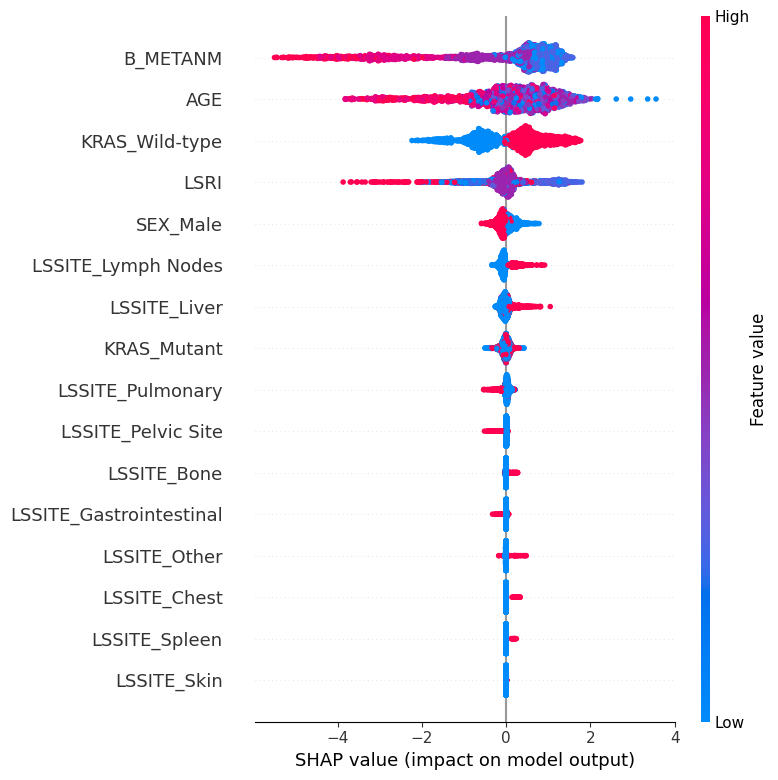

In [84]:
import shap
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_train)
shap.summary_plot(shap_values, X_train)

In [85]:
shap_importance = np.abs(shap_values).mean(axis=0)
feature_importance = pd.DataFrame(list(zip(X_train.columns, shap_importance)), columns=['Feature', 'Importance'])
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
print(feature_importance)

                    Feature  Importance
2                  B_METANM    1.260726
1                       AGE    0.837432
15           KRAS_Wild-type    0.677868
13                     LSRI    0.452586
0                  SEX_Male    0.134258
7        LSSITE_Lymph Nodes    0.123398
6              LSSITE_Liver    0.087060
14              KRAS_Mutant    0.065734
10         LSSITE_Pulmonary    0.051049
9        LSSITE_Pelvic Site    0.012277
3               LSSITE_Bone    0.008074
5   LSSITE_Gastrointestinal    0.006512
8              LSSITE_Other    0.006291
4              LSSITE_Chest    0.006177
12            LSSITE_Spleen    0.003040
11              LSSITE_Skin    0.000133


# CR (complete responce)

In [87]:
y1 = ntl_final['LSSLD_CR']

In [88]:
X_train, X_test, y_train, y_test = train_test_split(X, y1, test_size=0.2, random_state=42)

In [89]:
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb_random = RandomizedSearchCV(estimator=xgb, param_distributions=xgb_param_grid, 
                                n_iter=50, cv=5, verbose=1, random_state=42, n_jobs=-1)

xgb_random.fit(X_train, y_train)

xgb_best = xgb_random.best_estimator_

Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [90]:
print("XGBoost Classification Report:")
print(classification_report(y_test, xgb_best.predict(X_test)))

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       638

    accuracy                           1.00       638
   macro avg       1.00      1.00      1.00       638
weighted avg       1.00      1.00      1.00       638



# In Non Target Lesion we never achieved 100% (Complete) objective Responce